In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import numpy as np
import pandas as pd
from IPython.display import Image, display
from clima_ecuador import config
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
R = json.loads(config.RESULTADOS.read_text(encoding="utf-8"))
def figura(nombre, ancho=950):
    display(Image(filename=str(config.FIGURAS / nombre), width=ancho))
def reporte(nombre):
    return pd.read_csv(config.REPORTES / nombre)

# 04 · Eventos extremos: ¿aumentan?

Índices del **ETCCDI** calculados para cada ciudad y año. Los umbrales son relativos a cada ciudad: un "día cálido"
en Quito no es lo mismo que en Guayaquil.

* Calor: TX90p, TN90p (umbral = percentil 90 del día del año en 1981–2010, ventana de 5 días), olas de calor
  (≥ 3 días seguidos sobre p90), WSDI (≥ 6 días).
* Lluvia: R20mm, Rx1day, Rx5day, R95pTOT, SDII, días húmedos.
* Sequía: CDD (racha seca más larga) y rachas secas de ≥ 10 días.

In [2]:
from clima_ecuador import extremos
diario = pd.read_parquet(config.DIARIO)
quito = diario[diario["punto"] == "Quito"]
p90 = extremos.umbral_percentil(quito, "tmax")
print("Umbral p90 de Tmáx en Quito: entre", round(p90.min(), 1), "y", round(p90.max(), 1), "°C según el día del año")
extremos.indices_ciudad(quito).tail()

Umbral p90 de Tmáx en Quito: entre 17.6 y 19.9 °C según el día del año


,anio,tx90p,tn90p,dias_ola_calor,olas_calor,wsdi,prcptot,dias_lluvia,r20mm,rx1day,rx5day,r95ptot,sdii,cdd,rachas_secas_10
40,2020,32.240,32.787,74,14,41,"2,918.900",342,16,33.800,98.000,497.900,8.535,5,0
41,2021,19.452,22.740,26,6,12,"3,412.300",352,20,40.200,118.100,618.500,9.694,3,0
42,2022,5.205,12.329,6,2,0,"3,494.300",356,20,37.900,135.300,631.500,9.815,3,0
43,2023,29.315,38.630,77,20,15,"3,065.400",351,20,46.900,146.200,649.400,8.733,5,0
44,2024,31.148,43.169,71,16,20,"2,909.200",328,21,43.100,119.200,622.400,8.870,6,0


In [3]:
reporte("extremos_1980s_vs_ultima_decada.csv").round(2)

,indice,1981_1990,2015_2024,cambio
0,tx90p,10.640,27.300,16.670
1,tn90p,9.430,32.690,23.260
2,dias_ola_calor,13.470,52.070,38.600
3,olas_calor,2.680,10.380,7.700
4,wsdi,5.540,21.930,16.390
5,prcptot,"2,006.640","2,091.430",84.790
6,dias_lluvia,240.790,236.460,-4.330
7,r20mm,17.710,21.200,3.490
8,rx1day,60.820,64.340,3.520
9,rx5day,124.180,132.710,8.530


Promedio de las 22 ciudades, 1981–1990 frente a 2015–2024:
* **Días cálidos** de 10,6 % a 27,3 % y **noches cálidas** de 9,4 % a 32,7 % (por construcción son ~10 % en la normal).
* **Días en olas de calor: de 13 a 52 por año** (×3,9) y de 2,7 a 10,4 olas por año.
* La lluvia extrema cambia poco en promedio, salvo R95pTOT (+30 %), muy influida por la Amazonía (ver abajo).

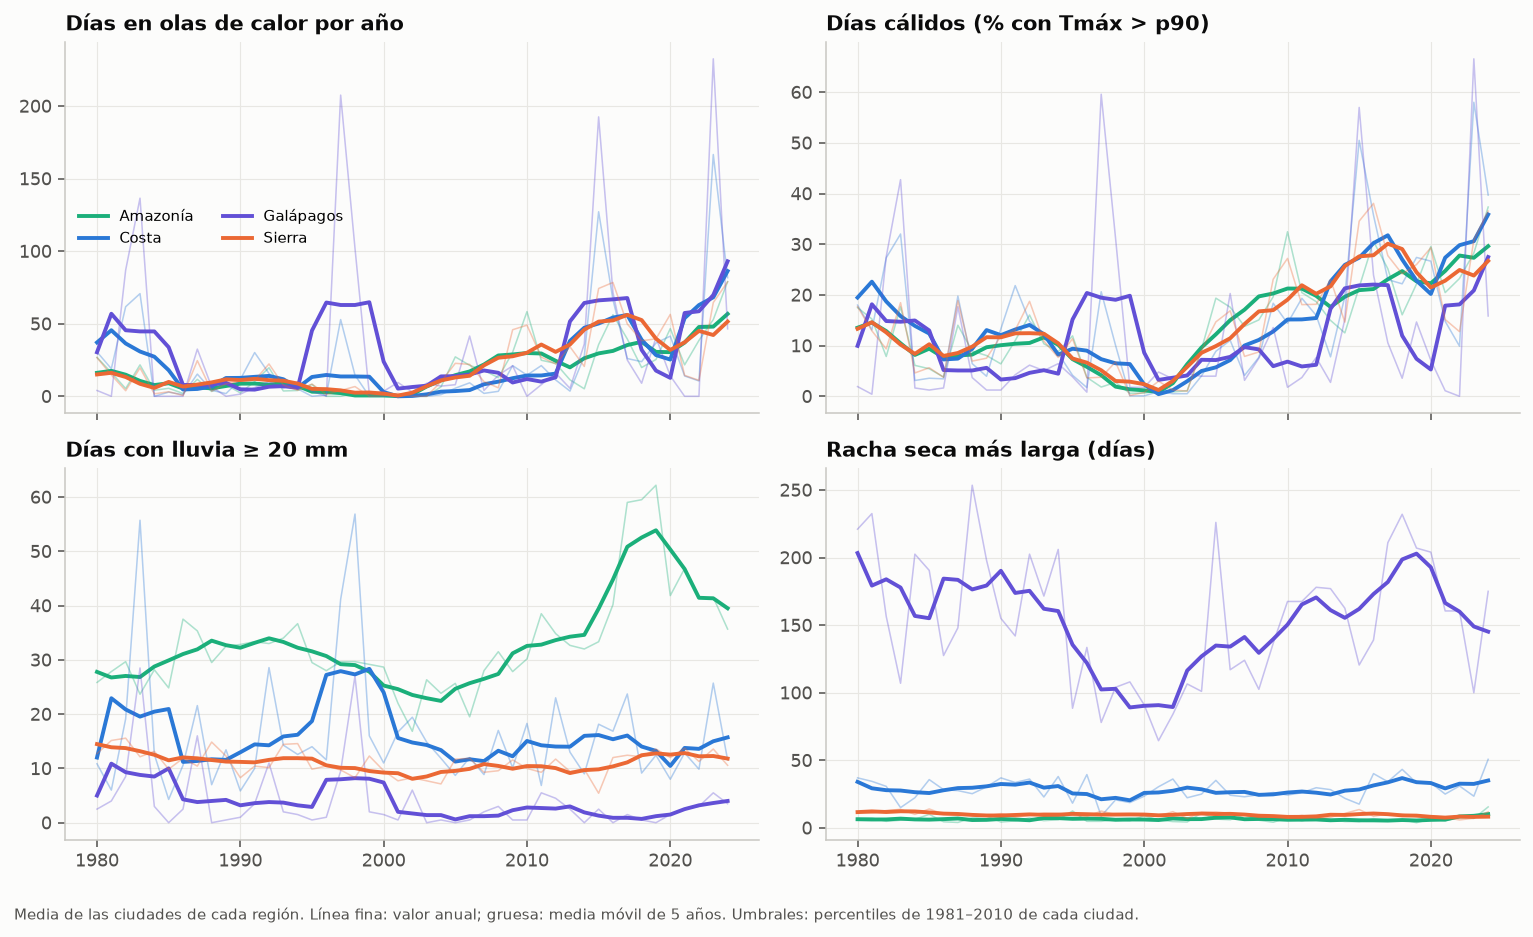

In [4]:
figura("09_extremos_regiones.png")

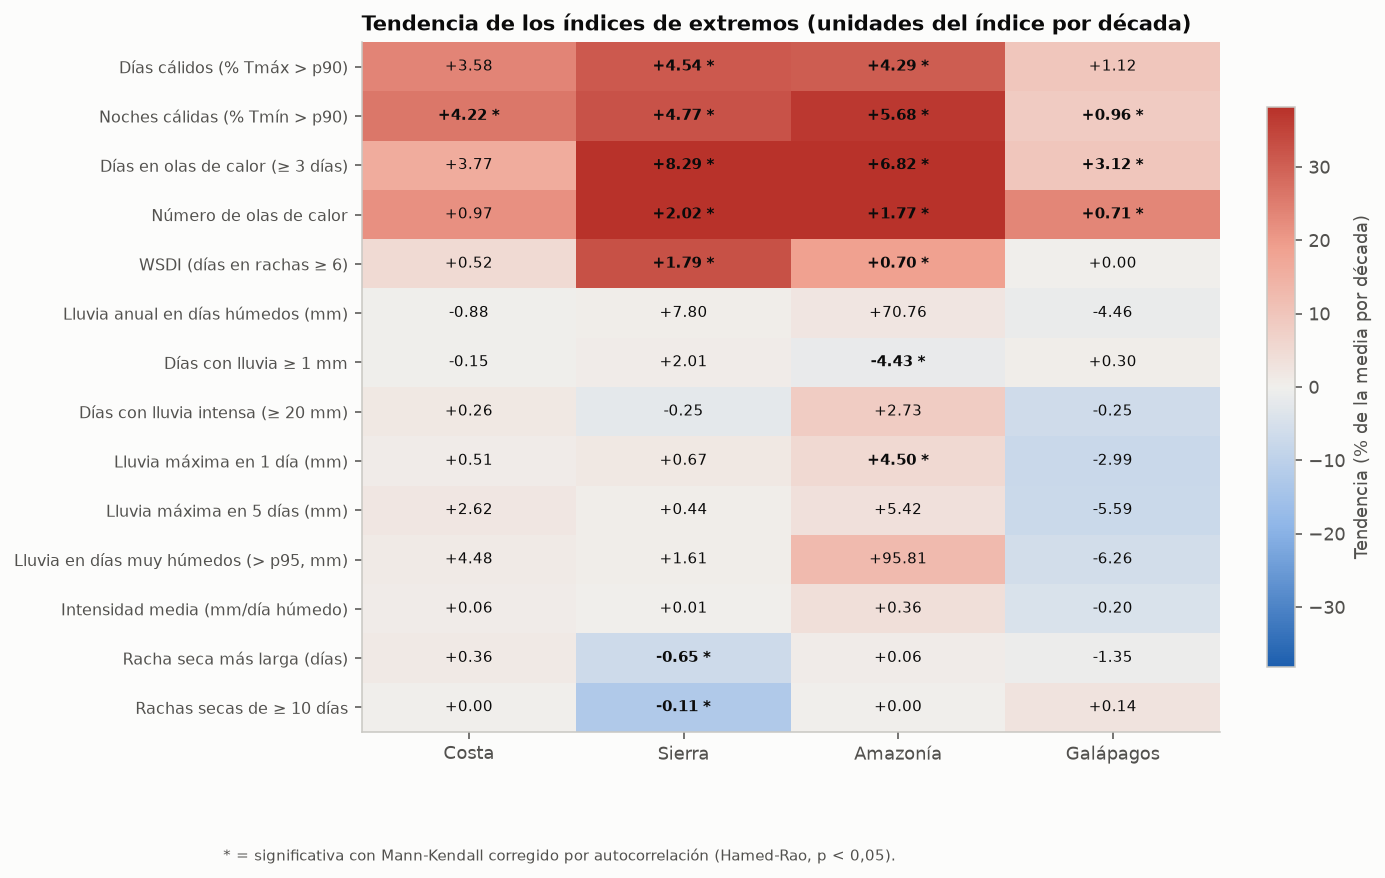

In [5]:
figura("10_extremos_tendencias.png", 820)

In [6]:
reporte("tendencias_extremos_regiones.csv").query("significativa")[
    ["region", "variable", "pendiente_decada", "p_hamed_rao"]].round(4)

,region,variable,pendiente_decada,p_hamed_rao
0,Amazonía,tx90p,4.294,0.003
1,Amazonía,tn90p,5.676,0.000
2,Amazonía,dias_ola_calor,6.823,0.012
3,Amazonía,olas_calor,1.771,0.007
4,Amazonía,wsdi,0.700,0.017
6,Amazonía,dias_lluvia,-4.428,0.002
8,Amazonía,rx1day,4.496,0.009
15,Costa,tn90p,4.223,0.006
29,Galápagos,tn90p,0.963,0.043
30,Galápagos,dias_ola_calor,3.125,0.023


* El calor extremo aumenta de forma significativa en la **Sierra y la Amazonía** (todos los índices de calor) y en
  las noches de la Costa. En la Sierra: **+8,3 días en olas de calor por década**.
* En la **Sierra las rachas secas se acortan** (CDD −0,65 días/década): coherente con un ERA5 que llueve casi todos los
  días en los Andes (en Izobamba, 98 % de días con ≥ 1 mm contra 67 % en la estación). No es un resultado robusto.
* **Amazonía**: menos días de lluvia (−4,4/década) pero más intensos (Rx1day +4,5 mm/década). Hay un **pulso
  anómalo en 2017–2019** en las 6 ciudades (Coca: 5 051 mm en 2018 frente a ~3 400 habituales) que las estaciones
  GHCN no permiten confirmar (tienen huecos justo en esos años). Las tendencias de lluvia amazónica son provisionales.

In [7]:
i = pd.read_parquet(config.ANUAL)
amazonia = ["Puyo", "Tena", "Nueva Loja", "Macas", "Zamora", "Coca"]
i[i["punto"].isin(amazonia)].pivot(index="anio", columns="punto", values="prcptot").loc[2012:2022].round(0)

punto,Coca,Macas,Nueva Loja,Puyo,Tena,Zamora
anio,,,,,,
2012,"3,698.000","4,585.000","3,250.000","2,421.000","3,516.000","1,969.000"
2013,"3,545.000","4,568.000","2,978.000","2,059.000","4,032.000","1,842.000"
2014,"3,412.000","4,498.000","2,973.000","2,348.000","4,219.000","1,769.000"
2015,"3,423.000","4,329.000","2,862.000","1,926.000","3,621.000","1,802.000"
2016,"3,548.000","4,807.000","3,301.000","2,477.000","3,833.000","1,903.000"
2017,"5,106.000","5,103.000","4,899.000","3,112.000","5,208.000","2,290.000"
2018,"5,051.000","5,606.000","4,762.000","3,130.000","5,365.000","2,052.000"
2019,"5,176.000","5,712.000","4,889.000","2,938.000","5,375.000","2,391.000"
2020,"3,532.000","4,545.000","3,393.000","2,420.000","3,894.000","1,787.000"
